#SI Project - World Happiness Report

##Name:- Sanika Bhoyar
##Roll no:- 22
##Batch:- B2-B2

Practical 1 — Web Scraping

In [53]:

import pandas as pd
import requests
import io

url = "https://en.wikipedia.org/wiki/World_Happiness_Report"

headers = {
    "User-Agent": "Mozilla/5.0"
}

print("Status Code:", response.status_code)

if response.status_code == 200:
    print("Website is working successfully!")
else:
    print("Website access failed!")

response = requests.get(url, headers=headers, timeout=20)
response.raise_for_status()

tables = pd.read_html(io.StringIO(response.text))

print("Total Tables:", len(tables))

# Show the table columns to identify the correct table
for i, table in enumerate(tables):
    print("\nTable Number:", i)
    print(table.columns.tolist())

# Find the overall country ranking table
df = None

for table in tables:
    columns = [str(col).lower() for col in table.columns]

    if (
        any("overall rank" in col for col in columns)
        and any("country" in col for col in columns)
        and any(
            "life evaluation" in col or "happiness score" in col
            for col in columns
        )
    ):
        df = table.copy()
        break

if df is not None:
    print("\nHappiness Ranking Table:")
    print(df.head())

    df.to_csv("happiness_scraped.csv", index=False)
    print("happiness_scraped.csv saved successfully")
else:
    print("Happiness ranking table not found.")


Total Tables: 40

Table Number: 0
['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Residual']

Table Number: 1
['Table', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9']

Table Number: 2
['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Residual']

Table Number: 3
['Table', 'Unnamed: 1', 'Unnamed: 2']

Table Number: 4
['Rank', 'Country or region', 'Life evaluation']

Table Number: 5
['Table', 'Unnamed: 1']

Table Number: 6
['Rank', 'Country or region']

Table Number: 7
['Table', 'Unnamed: 1']

Table Number: 8
['Rank', 'Country or region']

Table Number: 9
['Table', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unn

Practical 2 — Descriptive Statistics and Data Visualization

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("2015_world_happiness.csv")

df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df = df.dropna(subset=["Happiness Score"])

print(df.head())
print("Dataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns.tolist())
print("\nDataset Information:")
df.info()

print("\nMissing Values:\n", df.isnull().sum())

# Fill missing numeric values with their column median
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing values after cleaning:\n", df.isnull().sum())

       Country          Region  Happiness Rank  Happiness Score  \
0  Switzerland  Western Europe               1            7.587   
1      Iceland  Western Europe               2            7.561   
2      Denmark  Western Europe               3            7.527   
3       Norway  Western Europe               4            7.522   
4       Canada   North America               5            7.427   

   Standard Error  Economy (GDP per Capita)   Family  \
0         0.03411                   1.39651  1.34951   
1         0.04884                   1.30232  1.40223   
2         0.03328                   1.32548  1.36058   
3         0.03880                   1.45900  1.33095   
4         0.03553                   1.32629  1.32261   

   Health (Life Expectancy)  Freedom  Trust (Government Corruption)  \
0                   0.94143  0.66557                        0.41978   
1                   0.94784  0.62877                        0.14145   
2                   0.87464  0.64938           

In [55]:
# Select numerical columns
num_cols = df.select_dtypes(include="number").columns

# Descriptive statistics
print("Mean:\n", df[num_cols].mean())
print("\nMedian:\n", df[num_cols].median())
print("\nStandard Deviation:\n", df[num_cols].std())
print("\nVariance:\n", df[num_cols].var())
print("\nMinimum:\n", df[num_cols].min())
print("\nMaximum:\n", df[num_cols].max())
print("\nQuartiles:\n", df[num_cols].quantile([0.25, 0.50, 0.75]))
print("\nSummary:\n", df[num_cols].describe())

# Top 10 happiest countries
top10 = df.nlargest(10, "Happiness Score")

print("\nTop 10 Countries:\n",
      top10[["Country", "Happiness Score"]])


Mean:
 Happiness Rank                   79.493671
Happiness Score                   5.375734
Standard Error                    0.047885
Economy (GDP per Capita)          0.846137
Family                            0.991046
Health (Life Expectancy)          0.630259
Freedom                           0.428615
Trust (Government Corruption)     0.143422
Generosity                        0.237296
Dystopia Residual                 2.098977
dtype: float64

Median:
 Happiness Rank                   79.500000
Happiness Score                   5.232500
Standard Error                    0.043940
Economy (GDP per Capita)          0.910245
Family                            1.029510
Health (Life Expectancy)          0.696705
Freedom                           0.435515
Trust (Government Corruption)     0.107220
Generosity                        0.216130
Dystopia Residual                 2.095415
dtype: float64

Standard Deviation:
 Happiness Rank                   45.754363
Happiness Score             

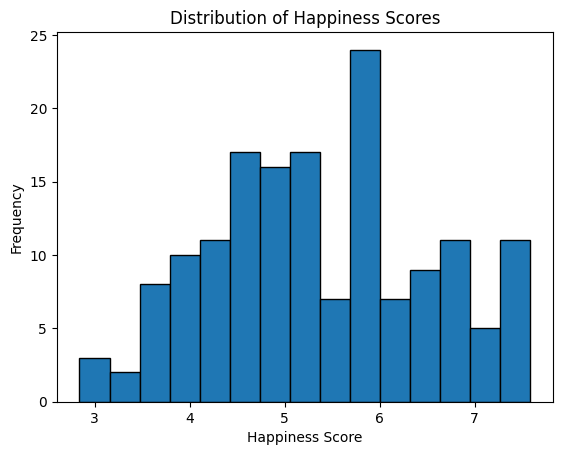

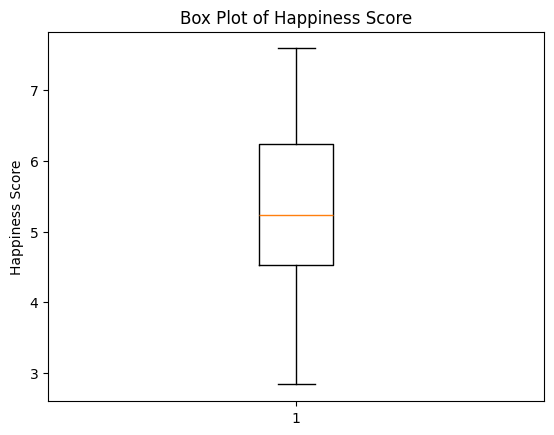

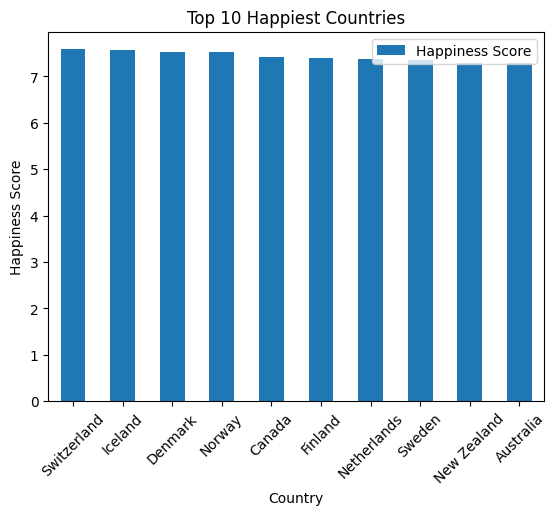

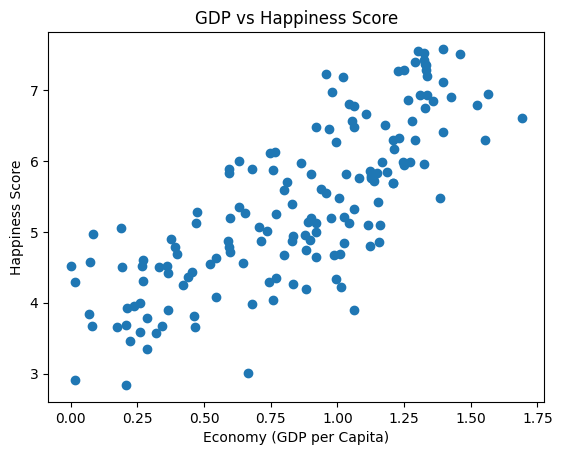

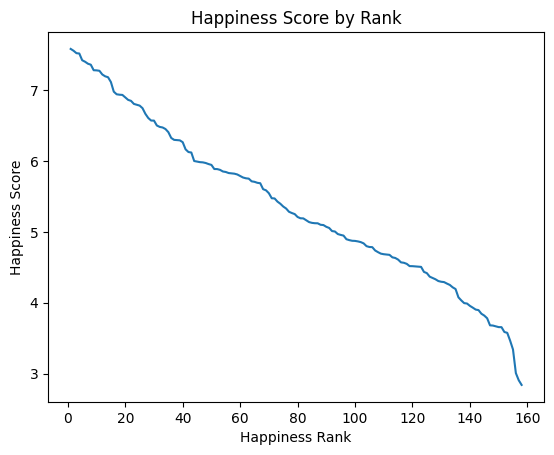

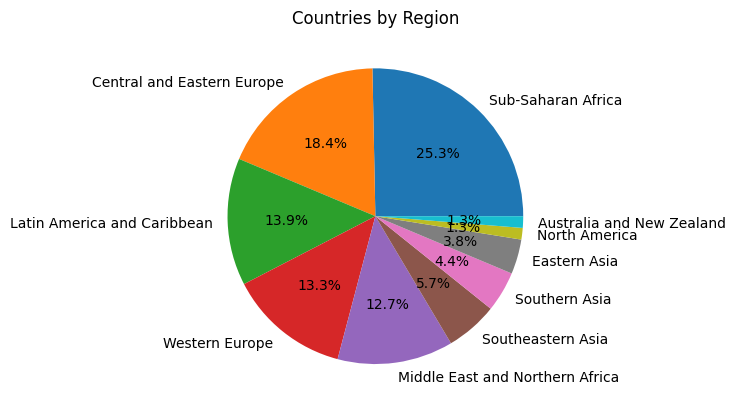

In [56]:
# Histogram
plt.hist(df["Happiness Score"], bins=15, edgecolor="black")
plt.title("Distribution of Happiness Scores")
plt.xlabel("Happiness Score")
plt.ylabel("Frequency")
plt.show()
print("\n")

# Box plot
plt.boxplot(df["Happiness Score"])
plt.title("Box Plot of Happiness Score")
plt.ylabel("Happiness Score")
plt.show()
print("\n")

# Bar chart
top10.plot(x="Country", y="Happiness Score", kind="bar")
plt.title("Top 10 Happiest Countries")
plt.ylabel("Happiness Score")
plt.xticks(rotation=45)
plt.show()
print("\n")

# Scatter plot
plt.scatter(df["Economy (GDP per Capita)"],
            df["Happiness Score"])
plt.title("GDP vs Happiness Score")
plt.xlabel("Economy (GDP per Capita)")
plt.ylabel("Happiness Score")
plt.show()
print("\n")

# Line plot
df_sorted = df.sort_values("Happiness Rank")

plt.plot(df_sorted["Happiness Rank"],
         df_sorted["Happiness Score"])
plt.title("Happiness Score by Rank")
plt.xlabel("Happiness Rank")
plt.ylabel("Happiness Score")
plt.show()
print("\n")

# Pie chart of countries by region
df["Region"].value_counts().plot(
    kind="pie", autopct="%1.1f%%"
)
plt.title("Countries by Region")
plt.ylabel("")
plt.show()

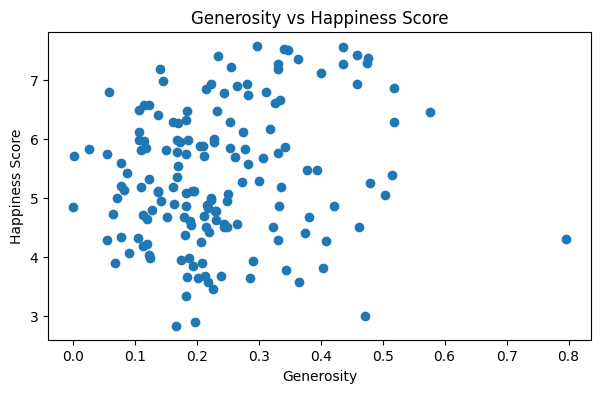

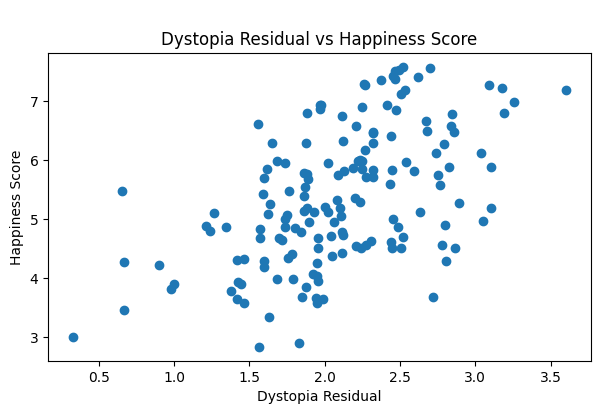

In [57]:
# Generosity vs Happiness Score
plt.figure(figsize=(7, 4))
plt.scatter(df["Generosity"], df["Happiness Score"])
plt.xlabel("Generosity")
plt.ylabel("Happiness Score")
plt.title("Generosity vs Happiness Score")
plt.show()
print("\n")

# Dystopia Residual vs Happiness Score
plt.figure(figsize=(7, 4))
plt.scatter(df["Dystopia Residual"], df["Happiness Score"])
plt.xlabel("Dystopia Residual")
plt.ylabel("Happiness Score")
plt.title("\nDystopia Residual vs Happiness Score")
plt.show()

Practical 3 — Probability and Normal Distribution

Mean: 5.376
Standard Deviation: 1.145
P(Score < 5): 0.3714
P(Score > 6): 0.2928
P(4 < Score < 6): 0.5924
Empirical P(Score > 6): 0.2785


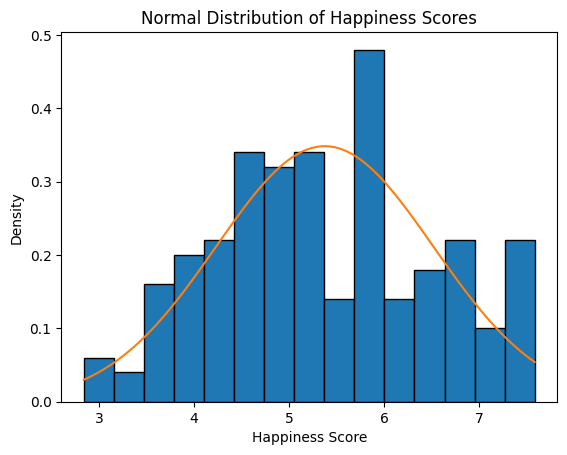


Random Sample:
 128    4.307
45     5.987
134    4.194
156    2.905
90     5.057
29     6.574
96     4.898
98     4.876
95     4.949
140    3.931
Name: Happiness Score, dtype: float64
Sample Mean: 4.768


In [58]:
from scipy.stats import norm

scores = df["Happiness Score"]

mean_score = scores.mean()
std_score = scores.std()

print("Mean:", round(mean_score, 3))
print("Standard Deviation:", round(std_score, 3))

# Probability that score is below 5
p_below_5 = norm.cdf(5, mean_score, std_score)
print("P(Score < 5):", round(p_below_5, 4))

# Probability that score is above 6
p_above_6 = 1 - norm.cdf(6, mean_score, std_score)
print("P(Score > 6):", round(p_above_6, 4))

# Probability that score lies between 4 and 6
p_between = (
    norm.cdf(6, mean_score, std_score)
    - norm.cdf(4, mean_score, std_score)
)
print("P(4 < Score < 6):", round(p_between, 4))

# Empirical probability
count = (scores > 6).sum()
empirical_probability = count / len(scores)

print("Empirical P(Score > 6):",
      round(empirical_probability, 4))

# Histogram with normal curve
x = np.linspace(scores.min(), scores.max(), 100)

plt.hist(scores, bins=15, density=True, edgecolor="black")
plt.plot(x, norm.pdf(x, mean_score, std_score))
plt.title("Normal Distribution of Happiness Scores")
plt.xlabel("Happiness Score")
plt.ylabel("Density")
plt.show()

# Random sample
sample = scores.sample(n=10, random_state=42)
print("\nRandom Sample:\n", sample)
print("Sample Mean:", round(sample.mean(), 3))

Practical 4 — Central Limit Theorem and Sampling Distribution

Population Mean: 5.376
Population SD: 1.145
Mean of Sample Means: 5.367
Standard Error: 0.209


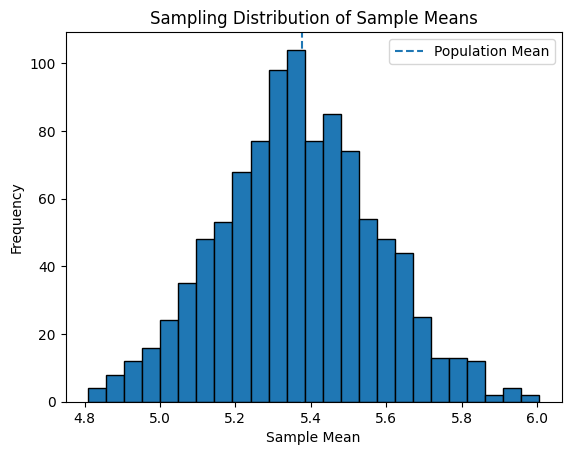

Sample Size: 10 | Mean: 5.386 | Standard Error: 0.362
Sample Size: 30 | Mean: 5.379 | Standard Error: 0.209
Sample Size: 50 | Mean: 5.381 | Standard Error: 0.162


In [59]:
population = df["Happiness Score"].values

population_mean = np.mean(population)
population_std = np.std(population, ddof=1)

print("Population Mean:", round(population_mean, 3))
print("Population SD:", round(population_std, 3))

# Take 1000 samples and calculate their means
sample_means = []

for i in range(1000):
    sample = np.random.choice(
        population, size=30, replace=True
    )
    sample_means.append(np.mean(sample))

print("Mean of Sample Means:",
      round(np.mean(sample_means), 3))

print("Standard Error:",
      round(population_std / np.sqrt(30), 3))

# Sampling distribution
plt.hist(sample_means, bins=25, edgecolor="black")
plt.axvline(population_mean, linestyle="--",
            label="Population Mean")
plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Compare different sample sizes
for n in [10, 30, 50]:
    means = []

    for i in range(500):
        sample = np.random.choice(
            population, size=n, replace=True
        )
        means.append(sample.mean())

    print(
        "Sample Size:", n,
        "| Mean:", round(np.mean(means), 3),
        "| Standard Error:",
        round(population_std / np.sqrt(n), 3)
    )

Practical 5 — Confidence Interval, Hypothesis Testing, Regression and Classification

Part A: Confidence interval and one-sample t-test

In [60]:
from scipy.stats import t, ttest_1samp

scores = df["Happiness Score"]

n = len(scores)
mean_score = scores.mean()
std_score = scores.std()

# 95% confidence interval
standard_error = std_score / np.sqrt(n)
critical_value = t.ppf(0.975, df=n-1)

lower = mean_score - critical_value * standard_error
upper = mean_score + critical_value * standard_error

print("Mean Happiness Score:", round(mean_score, 3))
print("95% Confidence Interval:",
      round(lower, 3), "to", round(upper, 3))

# H0: Population mean happiness score is 5
t_stat, p_value = ttest_1samp(scores, popmean=5)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Mean Happiness Score: 5.376
95% Confidence Interval: 5.196 to 5.556
T-statistic: 4.124771675872843
P-value: 6.000262214852154e-05
Reject H0


Part B: Compare regression models

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error

features = [
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity",
    "Dystopia Residual"
]

X = df[features]
y = df["Happiness Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    results.append([name, r2, mae, rmse])

result_df = pd.DataFrame(
    results, columns=["Model", "R2", "MAE", "RMSE"]
)

print(result_df.sort_values("R2", ascending=False))

               Model        R2       MAE      RMSE
0  Linear Regression  1.000000  0.000231  0.000270
1              Ridge  0.997085  0.049268  0.064304
5  Gradient Boosting  0.964760  0.177308  0.223599
4      Random Forest  0.940226  0.222420  0.291211
3      Decision Tree  0.816251  0.410094  0.510582
2              Lasso -0.005118  1.028968  1.194157


Part C: Classification — High or Low Happiness


Model: Logistic Regression
Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00        16

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32



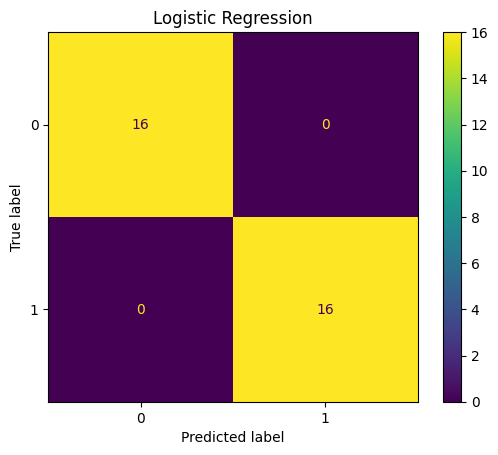


Model: Decision Tree
Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.93      0.81      0.87        16
           1       0.83      0.94      0.88        16

    accuracy                           0.88        32
   macro avg       0.88      0.88      0.87        32
weighted avg       0.88      0.88      0.87        32



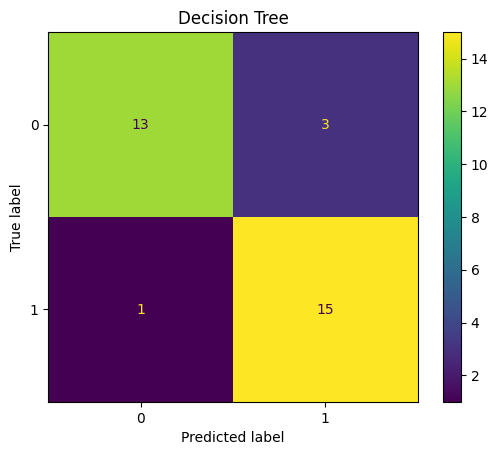


Model: Random Forest
Accuracy: 0.969
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        16
           1       1.00      0.94      0.97        16

    accuracy                           0.97        32
   macro avg       0.97      0.97      0.97        32
weighted avg       0.97      0.97      0.97        32



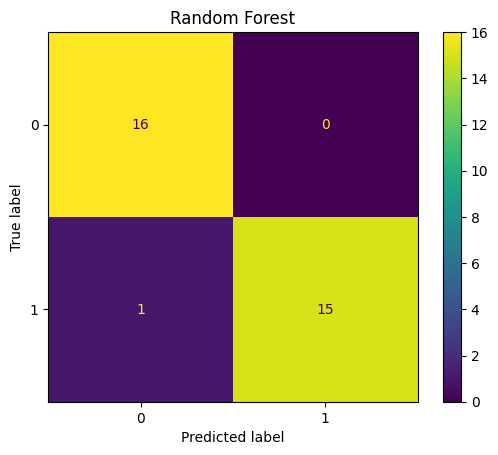

In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Define high and low happiness using the median
df["Happiness Level"] = np.where(
    df["Happiness Score"] >= df["Happiness Score"].median(),
    1, 0
)

X = df[features]
y = df["Happiness Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

class_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

for name, model in class_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\nModel:", name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 3))
    print(classification_report(y_test, pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(name)
    plt.show()

Practical 6 — Correlation, Covariance and Statistical Tests

Part A: Correlation and covariance

Covariance:
                                Happiness Score  Economy (GDP per Capita)  \
Happiness Score                       1.311048                  0.360476   
Economy (GDP per Capita)              0.360476                  0.162506   
Family                                0.230969                  0.070852   
Health (Life Expectancy)              0.204881                  0.081323   
Freedom                               0.098042                  0.022495   
Trust (Government Corruption)         0.054316                  0.014898   
Generosity                            0.026156                 -0.000534   
Dystopia Residual                     0.336225                  0.008939   

                                 Family  Health (Life Expectancy)   Freedom  \
Happiness Score                0.230969                  0.204881  0.098042   
Economy (GDP per Capita)       0.070852                  0.081323  0.022495   
Family                         0.074185                  0.035741

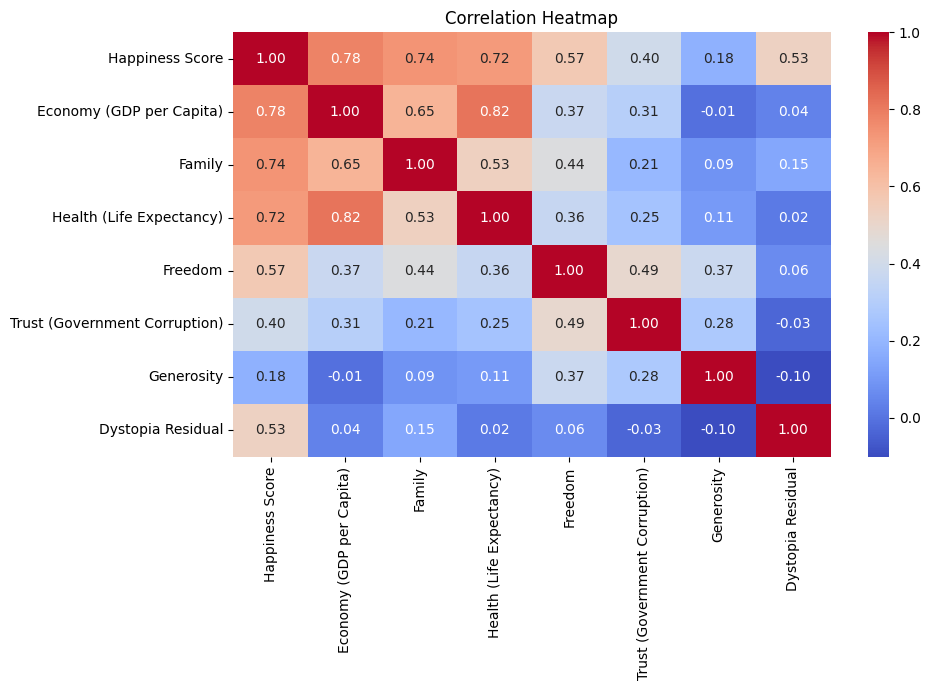

In [63]:
cols = [
    "Happiness Score",
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity",
    "Dystopia Residual"
]

print("Covariance:\n", df[cols].cov())
print("Pearson correlation:\n", df[cols].corr(method="pearson"))
print("Spearman correlation:\n", df[cols].corr(method="spearman"))

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Part B: Pearson and Spearman significance tests

In [64]:
from scipy.stats import pearsonr, spearmanr

x = df["Economy (GDP per Capita)"]
y = df["Happiness Score"]

r, p = pearsonr(x, y)
print("Pearson Correlation:", round(r, 3))
print("Pearson P-value:", p)

r_s, p_s = spearmanr(x, y)
print("Spearman Correlation:", round(r_s, 3))
print("Spearman P-value:", p_s)

Pearson Correlation: 0.781
Pearson P-value: 1.0505384131958295e-33
Spearman Correlation: 0.796
Spearman P-value: 8.572517012563218e-36


Part C: Independent t-test, ANOVA and chi-square test

In [65]:
from scipy.stats import ttest_ind, f_oneway
from scipy.stats import chi2_contingency

# Independent t-test: compare two regions
regions = df["Region"].value_counts().index[:2].tolist()

a = df.loc[
    df["Region"] == regions[0], "Happiness Score"
]
b = df.loc[
    df["Region"] == regions[1], "Happiness Score"
]

t_stat, p_value = ttest_ind(a, b, equal_var=False)

print("Regions:", regions)
print("T-test P-value:", p_value)

# ANOVA: compare happiness scores across up to 3 regions
groups = [
    group["Happiness Score"].values
    for _, group in df.groupby("Region")
    if len(group) >= 5
]

f_stat, p_anova = f_oneway(*groups[:3])

print("ANOVA F-statistic:", f_stat)
print("ANOVA P-value:", p_anova)

# Chi-square: Region vs High/Low Happiness
temp = df[["Region", "Happiness Score"]].copy()

temp["Happiness Level"] = np.where(
    temp["Happiness Score"] >= temp["Happiness Score"].median(),
    "High", "Low"
)

table = pd.crosstab(
    temp["Region"], temp["Happiness Level"]
)

chi2, p_chi, dof, expected = chi2_contingency(table)

print("Chi-square Statistic:", chi2)
print("Chi-square P-value:", p_chi)
print("Degrees of Freedom:", dof)

Regions: ['Sub-Saharan Africa', 'Central and Eastern Europe']
T-test P-value: 5.697002883825925e-11
ANOVA F-statistic: 10.234258357651548
ANOVA P-value: 0.00017036034852529038
Chi-square Statistic: 66.18195750609543
Chi-square P-value: 8.492680214779046e-11
Degrees of Freedom: 9


Part D: Paired t-test of actual and predicted scores

In [66]:
from scipy.stats import ttest_rel
from sklearn.linear_model import LinearRegression

X = df[features]
y = df["Happiness Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)

t_stat, p_value = ttest_rel(y_test, pred)

print("Paired T-test Statistic:", t_stat)
print("Paired T-test P-value:", p_value)

Paired T-test Statistic: -0.45677181900693087
Paired T-test P-value: 0.6510196884013753


In [67]:
X = df[features]
y = df["Happiness Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

mlr = LinearRegression()
mlr.fit(X_train, y_train)

pred = mlr.predict(X_test)

print("R2:", round(r2_score(y_test, pred), 3))
print("MAE:", round(mean_absolute_error(y_test, pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

importance = pd.DataFrame({
    "Predictor": features,
    "Coefficient": mlr.coef_
})

print(importance.sort_values(
    "Coefficient", key=abs, ascending=False
))
print("Intercept:", round(mlr.intercept_, 3))

R2: 1.0
MAE: 0.0
RMSE: 0.0
                       Predictor  Coefficient
0       Economy (GDP per Capita)     1.000118
6              Dystopia Residual     1.000028
4  Trust (Government Corruption)     0.999990
1                         Family     0.999968
2       Health (Life Expectancy)     0.999911
5                     Generosity     0.999909
3                        Freedom     0.999836
Intercept: 0.0


Practical 7 — Simple Linear Regression and Model Comparison

               Model        R2       MAE      RMSE
1              Ridge  0.642343  0.588409  0.712338
0  Linear Regression  0.641928  0.588015  0.712752
4      Random Forest  0.385110  0.734622  0.934010
2              Lasso -0.005118  1.028968  1.194157
3      Decision Tree -0.032048  0.943625  1.210049


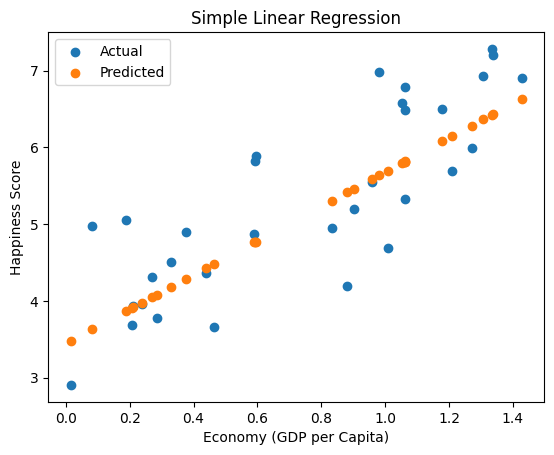

Predicted Happiness Score: 5.68


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error

X = df[["Economy (GDP per Capita)"]]
y = df["Happiness Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

results = []

for name, model in models.items():

    # Scale input for linear and regularized models
    if name in ["Linear Regression", "Ridge", "Lasso"]:
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

    results.append([
        name,
        r2_score(y_test, pred),
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred))
    ])

result_df = pd.DataFrame(
    results, columns=["Model", "R2", "MAE", "RMSE"]
)

print(result_df.sort_values("R2", ascending=False))

# Simple Linear Regression plot
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

pred = simple_model.predict(X_test)

plt.scatter(X_test, y_test, label="Actual")
plt.scatter(X_test, pred, label="Predicted")
plt.xlabel("Economy (GDP per Capita)")
plt.ylabel("Happiness Score")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

# Example prediction
example = pd.DataFrame({
    "Economy (GDP per Capita)": [1.0]
})

print("Predicted Happiness Score:",
      round(simple_model.predict(example)[0], 2))

Practical 8 — Multiple Linear Regression and Model Saving

In [68]:
import pandas as pd
import numpy as np
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Use the overall World Happiness Report table
df = tables[0].copy()

# Select input features
features = [
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption",
    "Residual"
]

# Input and target
X = df[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df["Life evaluation"], errors="coerce")

# Remove missing values
clean_df = pd.concat([X, y.rename("Life evaluation")], axis=1).dropna()

X = clean_df[features]
y = clean_df["Life evaluation"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
mlr = LinearRegression()
mlr.fit(X_train, y_train)

# Make predictions
pred = mlr.predict(X_test)

# Evaluate the model
print("R2 Score:", round(r2_score(y_test, pred), 3))
print("MAE:", round(mean_absolute_error(y_test, pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

# Display feature coefficients
importance = pd.DataFrame({
    "Feature": features,
    "Coefficient": mlr.coef_
})

print("\nFeature Coefficients:")
print(importance.sort_values(
    "Coefficient", key=abs, ascending=False
))

print("Intercept:", round(mlr.intercept_, 3))

# Predict happiness for an example input
example = pd.DataFrame([{
    "GDP per capita": 1.0,
    "Social support": 1.0,
    "Healthy life expectancy": 0.7,
    "Freedom to make life choices": 0.5,
    "Generosity": 0.1,
    "Perceptions of corruption": 0.2,
    "Residual": 1.5
}])

score = mlr.predict(example)[0]
print("Predicted Happiness Score:", round(score, 2))

# Save the model
joblib.dump(
    {"model": mlr, "features": features},
    "happiness_model.pkl"
)

print("Model saved successfully.")

R2 Score: 1.0
MAE: 0.001
RMSE: 0.001

Feature Coefficients:
                        Feature  Coefficient
3  Freedom to make life choices     1.000640
5     Perceptions of corruption     1.000410
1                Social support     1.000339
6                      Residual     1.000183
4                    Generosity     0.999626
2       Healthy life expectancy     0.999516
0                GDP per capita     0.999498
Intercept: -0.0
Predicted Happiness Score: 5.0
Model saved successfully.


In [29]:
import joblib
import pandas as pd

# Load the saved model
saved = joblib.load("happiness_model.pkl")

loaded_model = saved["model"]
features = saved["features"]

# Example input with correct column names
example = pd.DataFrame([{
    "GDP per capita": 1.0,
    "Social support": 1.0,
    "Healthy life expectancy": 0.7,
    "Freedom to make life choices": 0.5,
    "Generosity": 0.1,
    "Perceptions of corruption": 0.2,
    "Residual": 1.5
}])[features]

# Predict happiness score
prediction = loaded_model.predict(example)

print("Predicted Happiness Score:", round(prediction[0], 2))

Predicted Happiness Score: 5.0


In [30]:
import joblib

joblib.dump(
    {"model": mlr, "features": features},
    "happiness_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [31]:
from google.colab import files
files.download("happiness_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>